In [1]:
import pandas as pd

cars = pd.read_csv("../data/processed/vehicle_sales_clean.csv")


In [2]:
cars.shape

(558811, 19)

# Used Vehicle Exploratory Data Analysis

This notebook explores patterns in the cleaned vehicle sales dataset.

The goal is to understand how factors such as vehicle age, mileage, condition, make, model, and market value relate to selling price before building predictive models.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cars = pd.read_csv("../data/processed/vehicle_sales_clean.csv")

In [4]:
print("Dataset shape:", cars.shape)
cars.head()

Dataset shape: (558811, 19)


,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate,sale_year,vehicle_age,identity_missing
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0,2014-12-16 20:30:00+00:00,2014.0,-1.0,False
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0,2014-12-16 20:30:00+00:00,2014.0,-1.0,False
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,4.5,1331.0,gray,black,financial services remarketing (lease),31900.0,30000.0,2015-01-15 12:30:00+00:00,2015.0,1.0,False
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,4.1,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0,2015-01-29 12:30:00+00:00,2015.0,0.0,False
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,4.3,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0,2014-12-18 20:30:00+00:00,2014.0,0.0,False


In [5]:
cars.info()

<class 'pandas.DataFrame'>
RangeIndex: 558811 entries, 0 to 558810
Data columns (total 19 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   year              558811 non-null  int64  
 1   make              548510 non-null  str    
 2   model             548412 non-null  str    
 3   trim              548160 non-null  str    
 4   body              545616 non-null  str    
 5   transmission      493459 non-null  str    
 6   vin               558811 non-null  str    
 7   state             558811 non-null  str    
 8   condition         547017 non-null  float64
 9   odometer          558645 non-null  float64
 10  color             533377 non-null  str    
 11  interior          540986 non-null  str    
 12  seller            558811 non-null  str    
 13  mmr               558799 non-null  float64
 14  sellingprice      558795 non-null  float64
 15  saledate          558799 non-null  str    
 16  sale_year         558799 non-nu

In [6]:
cars["saledate"].dtype

<StringDtype(storage='python', na_value=nan)>

In [7]:
cars["saledate"] = pd.to_datetime(
    cars["saledate"],
    utc=True
)

In [8]:
cars["saledate"].dtype

datetime64[us, UTC]

In [9]:
cars.info()

<class 'pandas.DataFrame'>
RangeIndex: 558811 entries, 0 to 558810
Data columns (total 19 columns):
 #   Column            Non-Null Count   Dtype              
---  ------            --------------   -----              
 0   year              558811 non-null  int64              
 1   make              548510 non-null  str                
 2   model             548412 non-null  str                
 3   trim              548160 non-null  str                
 4   body              545616 non-null  str                
 5   transmission      493459 non-null  str                
 6   vin               558811 non-null  str                
 7   state             558811 non-null  str                
 8   condition         547017 non-null  float64            
 9   odometer          558645 non-null  float64            
 10  color             533377 non-null  str                
 11  interior          540986 non-null  str                
 12  seller            558811 non-null  str                


## 1. Selling Price Distribution

The selling-price distribution provides a basic view of the used vehicle market in the dataset.

This analysis will examine the typical selling-price range, identify skewness, and look for unusually high-priced vehicles that may affect later analysis and modeling.

In [10]:
cars["sellingprice"].describe()

count    558795.000000
mean      13611.453723
std        9749.695089
min         100.000000
25%        6900.000000
50%       12100.000000
75%       18200.000000
max      230000.000000
Name: sellingprice, dtype: float64

In [11]:
cars["sellingprice"].quantile([
    0.90,
    0.95,
    0.99,
    0.999
])

0.900    25500.0
0.950    30600.0
0.990    44900.0
0.999    78000.0
Name: sellingprice, dtype: float64

### Selling Price Findings

The median selling price is $12,100, while the mean is approximately $13,611. The higher mean suggests that the distribution is right-skewed by relatively expensive vehicles.

About 95% of vehicles sold for $30,600 or less, and 99% sold for $44,900 or less. The maximum selling price is $230,000, showing that a small number of high-priced vehicles create a long upper tail.

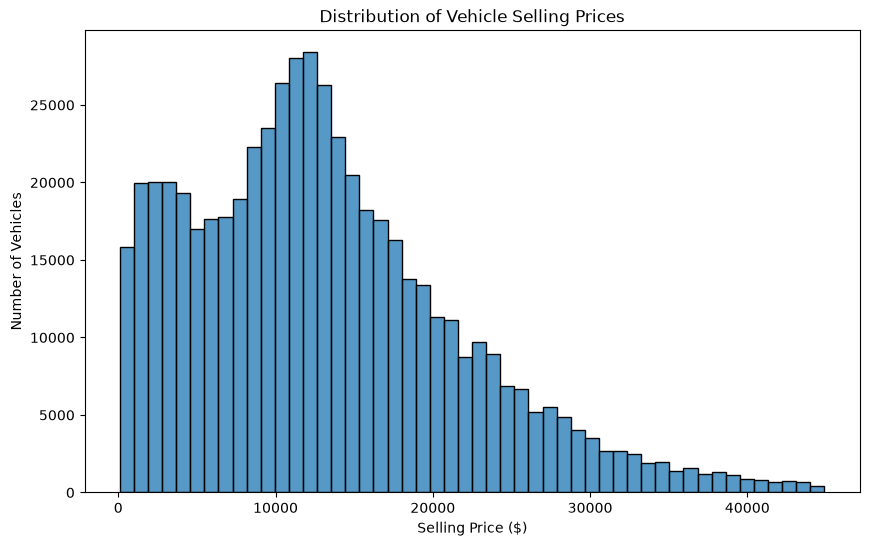

In [12]:
price_99 = cars["sellingprice"].quantile(0.99)

plt.figure(figsize=(10, 6))

sns.histplot(
    data=cars[cars["sellingprice"] <= price_99],
    x="sellingprice",
    bins=50
)

plt.title("Distribution of Vehicle Selling Prices")
plt.xlabel("Selling Price ($)")
plt.ylabel("Number of Vehicles")

plt.show()

### Selling Price Findings

The median selling price is $12,100, while the mean is approximately $13,611. The higher mean suggests that the distribution is right-skewed by relatively expensive vehicles.

About 95% of vehicles sold for $30,600 or less, while 99% sold for $44,900 or less. The maximum selling price is $230,000, showing that a small number of high-priced vehicles create a long upper tail.

The histogram also shows that most vehicles are concentrated in the lower and middle price ranges, with the number of vehicles generally decreasing as selling price increases.

## 2. Vehicle Age vs. Selling Price

Vehicle age is expected to have a strong relationship with selling price because vehicles generally lose value as they get older.

This section compares vehicle age with typical selling price to see how depreciation appears in the dataset.

In [13]:
age_price = (
    cars.groupby("vehicle_age")["sellingprice"]
    .median()
    .reset_index()
)

age_price

,vehicle_age,sellingprice
0,-1.0,21000.0
1,0.0,20400.0
2,1.0,17400.0
3,2.0,14500.0
4,3.0,14400.0
5,4.0,14400.0
6,5.0,10400.0
7,6.0,8800.0
8,7.0,8000.0
9,8.0,6500.0


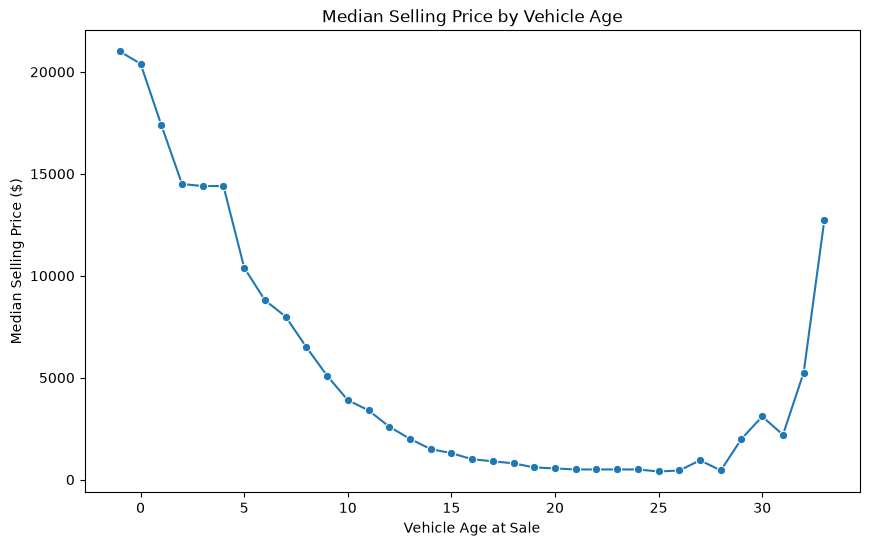

In [14]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=age_price,
    x="vehicle_age",
    y="sellingprice",
    marker="o"
)

plt.title("Median Selling Price by Vehicle Age")
plt.xlabel("Vehicle Age at Sale")
plt.ylabel("Median Selling Price ($)")

plt.show()

In [15]:
age_counts = (
    cars["vehicle_age"]
    .value_counts()
    .sort_index()
)

age_counts

vehicle_age
-1.0       201
 0.0     14369
 1.0     82639
 2.0     98970
 3.0     99851
 4.0     46203
 5.0     26041
 6.0     21892
 7.0     31749
 8.0     30574
 9.0     26328
 10.0    20945
 11.0    16862
 12.0    12908
 13.0     9136
 14.0     6299
 15.0     4904
 16.0     3149
 17.0     2030
 18.0     1454
 19.0      814
 20.0      629
 21.0      368
 22.0      197
 23.0      117
 24.0       64
 25.0       42
 26.0       16
 27.0       14
 28.0        6
 29.0       13
 30.0        7
 31.0        5
 32.0        1
 33.0        2
Name: count, dtype: int64

In [16]:
cars[cars["vehicle_age"] >= 25][
    ["vehicle_age", "make", "model", "sellingprice"]
].sort_values(["vehicle_age", "sellingprice"], ascending=[True, False])

,vehicle_age,make,model,sellingprice
363610,25.0,Chevrolet,C/K 1500 Series,11500.0
293302,25.0,Chevrolet,C/K 1500 Series,8000.0
552691,25.0,Chevrolet,Corvette,4100.0
435603,25.0,Chevrolet,Corvette,3700.0
361577,25.0,NaN,NaN,2500.0
...,...,...,...,...
174101,31.0,NaN,NaN,1800.0
182345,31.0,NaN,NaN,1100.0
368682,32.0,NaN,NaN,5250.0
530870,33.0,NaN,NaN,20500.0


Median selling price generally decreases as vehicle age increases. Some of the oldest vehicle groups show higher median prices, which may partly reflect collectible or vintage vehicles. However, these age groups contain very few vehicles, so their median prices are much less stable and should not be interpreted as evidence that vehicles generally increase in value at older ages.

## 3. Mileage vs. Selling Price

Mileage is expected to have a negative relationship with selling price because vehicles with more miles generally experience more wear and have less remaining useful life.

This section examines how typical selling prices change as mileage increases.

In [17]:
cars["mileage_bin"] = (
    (cars["odometer"] // 10000) * 10000
)

In [18]:
mileage_price = (
    cars.groupby("mileage_bin")["sellingprice"]
    .agg(["median", "count"])
    .reset_index()
)

mileage_price.head(20)

,mileage_bin,median,count
0,0.0,19200.0,25757
1,10000.0,18600.0,58422
2,20000.0,17400.0,66787
3,30000.0,15500.0,70814
4,40000.0,14300.0,48325
5,50000.0,12200.0,41017
6,60000.0,11500.0,31737
7,70000.0,10000.0,26163
8,80000.0,8800.0,25646
9,90000.0,7700.0,26766


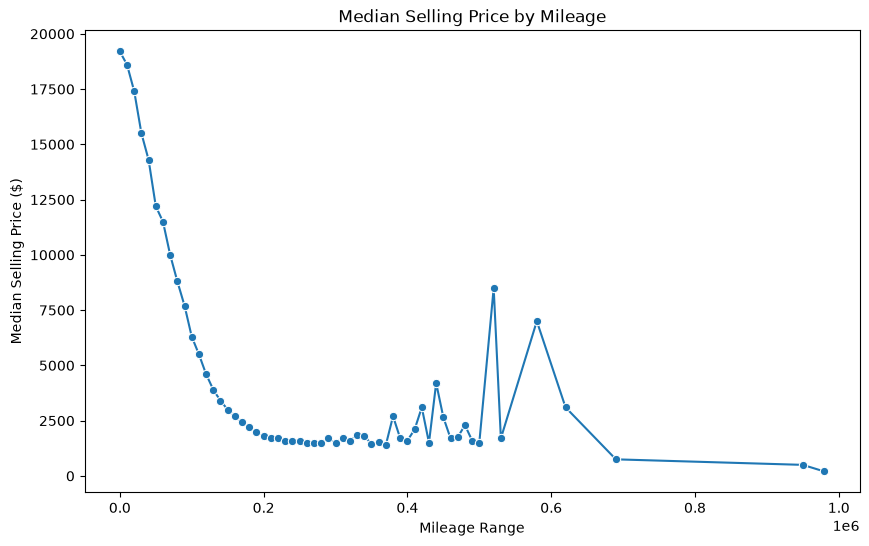

In [19]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=mileage_price,
    x="mileage_bin",
    y="median",
    marker="o"
)

plt.title("Median Selling Price by Mileage")
plt.xlabel("Mileage Range")
plt.ylabel("Median Selling Price ($)")

plt.show()

In [20]:
mileage_price[
    mileage_price["mileage_bin"] >= 300000
]

,mileage_bin,median,count
30,300000.0,1500.0,151
31,310000.0,1700.0,130
32,320000.0,1600.0,90
33,330000.0,1850.0,64
34,340000.0,1800.0,53
35,350000.0,1450.0,44
36,360000.0,1550.0,32
37,370000.0,1400.0,29
38,380000.0,2700.0,15
39,390000.0,1700.0,13


### Mileage Findings

Median selling price generally decreases as mileage increases. Vehicles with less than 10,000 miles have a median selling price of about $19,200, while vehicles with 100,000–109,999 miles have a median of about $6,300.

The relationship becomes less stable at extremely high mileage because very few vehicles exist in those ranges. For example, some mileage bins above 480,000 miles contain only one vehicle, causing individual cars to create large spikes in the median price.

These high-mileage vehicles are still kept in the dataset because their values may be legitimate, but the extreme mileage bins should not be interpreted as representing the general used-vehicle market.

## 4. Vehicle Condition vs. Selling Price

Vehicle condition is expected to have a positive relationship with selling price because better-condition vehicles generally require fewer repairs and are more desirable to buyers.

This section compares vehicle condition scores with median selling prices to see how strongly condition relates to market value.

In [21]:
condition_price = (
    cars.groupby("condition")["sellingprice"]
    .agg(["median", "count"])
    .reset_index()
)

condition_price

,condition,median,count
0,1.0,1700.0,7363
1,1.1,3100.0,87
2,1.2,2500.0,95
3,1.3,2675.0,82
4,1.4,2500.0,134
5,1.5,2600.0,144
6,1.6,3350.0,178
7,1.7,2600.0,243
8,1.8,3300.0,323
9,1.9,3600.0,42276


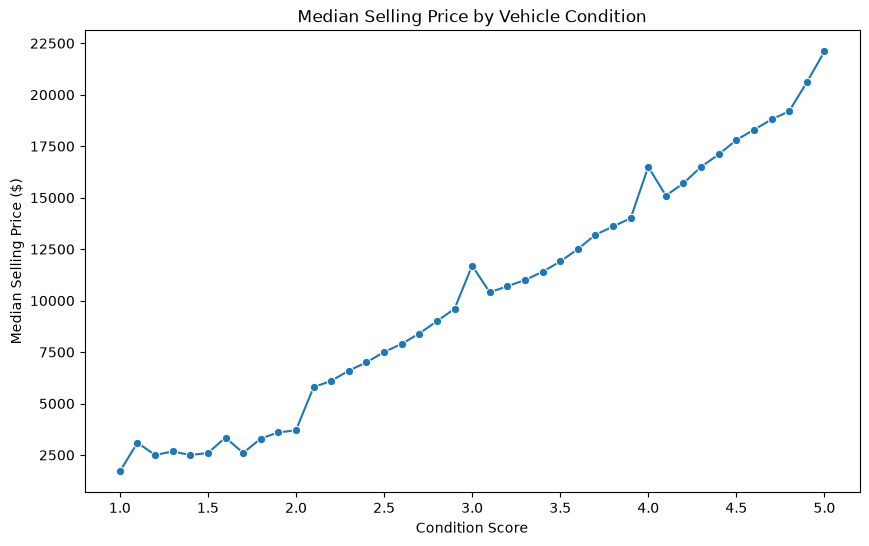

In [22]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=condition_price,
    x="condition",
    y="median",
    marker="o"
)

plt.title("Median Selling Price by Vehicle Condition")
plt.xlabel("Condition Score")
plt.ylabel("Median Selling Price ($)")

plt.show()

### Condition Findings

Median selling price generally increases as vehicle condition improves, showing a strong positive relationship between condition and market value.

Vehicles with low condition scores tend to have much lower median selling prices, while vehicles near the top of the 1.0–5.0 condition scale sell for substantially more.

The relationship is not perfectly smooth because selling price is also affected by factors such as vehicle age, mileage, make, and model.

## 5. Vehicle Make vs. Selling Price

Vehicle make can strongly affect selling price because brands differ in vehicle type, reliability, luxury level, performance, and original price.

To avoid drawing conclusions from brands with very few vehicles, this analysis will focus on makes with a large number of sales in the dataset.

In [23]:
make_price = (
    cars.groupby("make")["sellingprice"]
    .agg(["median", "count"])
    .reset_index()
)

make_price

,make,median,count
0,Acura,14800.0,5926
1,Aston Martin,51000.0,25
2,Audi,18500.0,5877
3,BMW,20100.0,20793
4,Bentley,62250.0,116
...,...,...,...
61,mazda tk,6500.0,1
62,mercedes,6000.0,70
63,mercedes-b,13650.0,2
64,smart,6000.0,396


In [24]:
make_price_reliable = make_price[
    make_price["count"] >= 5000
].sort_values("median", ascending=False)

make_price_reliable

,make,median,count
33,Mercedes-Benz,21000.0,17140
20,Infiniti,20600.0,15305
27,Lexus,20600.0,11980
3,BMW,20100.0,20793
2,Audi,18500.0,5877
28,Lincoln,17100.0,5786
15,GMC,16500.0,10638
46,Subaru,16400.0,5103
0,Acura,14800.0,5926
6,Cadillac,14000.0,7629


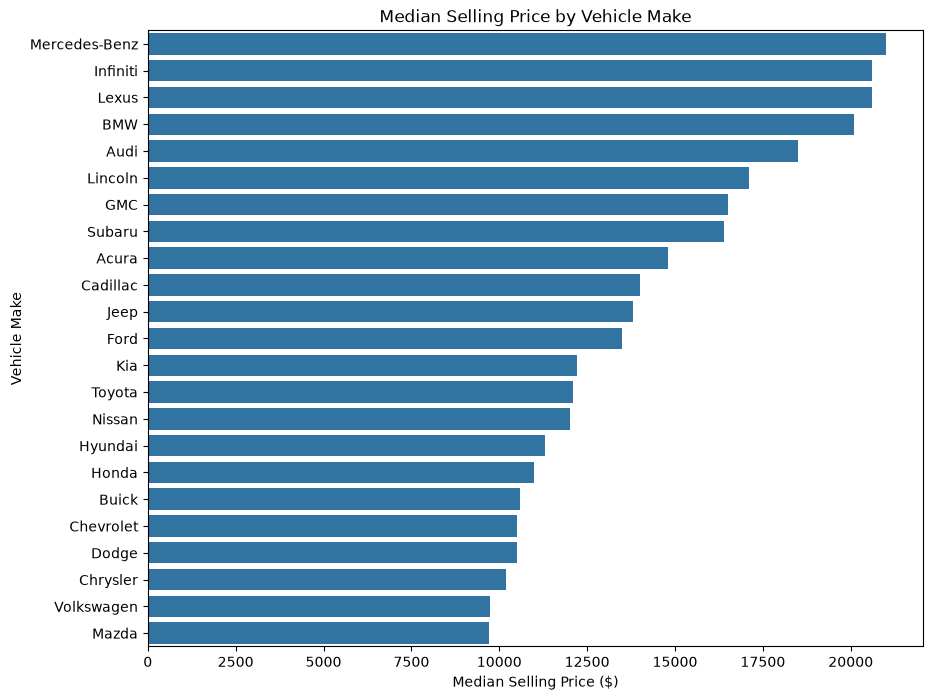

In [25]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=make_price_reliable,
    x="median",
    y="make"
)

plt.title("Median Selling Price by Vehicle Make")
plt.xlabel("Median Selling Price ($)")
plt.ylabel("Vehicle Make")

plt.show()

In [26]:
suspect_makes = [
    "mercedes",
    "mercedes-b",
    "vw",
    "mazda tk"
]

cars[cars["make"].isin(suspect_makes)][
    ["make", "model", "year", "body", "sellingprice"]
].sort_values("make").head(100)

,make,model,year,body,sellingprice
18664,mazda tk,CX-7,2007,NaN,6500.0
3499,mercedes,c230wz,2007,NaN,5300.0
71915,mercedes,c230wz,2007,NaN,9500.0
71912,mercedes,c230wz,2007,NaN,6000.0
66744,mercedes,c230wz,2007,NaN,5900.0
...,...,...,...,...,...
65522,vw,Jetta,2011,NaN,8400.0
65518,vw,Jetta,2011,NaN,7800.0
65506,vw,Jetta,2011,NaN,13400.0
65502,vw,Jetta,2011,NaN,7600.0


In [27]:
cars[cars["make"].isin(suspect_makes)]["make"].value_counts()

make
mercedes      70
vw            24
mercedes-b     2
mazda tk       1
Name: count, dtype: int64

### Make Findings

Median selling price varies substantially across major vehicle makes. Luxury brands such as Mercedes-Benz, Infiniti, Lexus, BMW, and Audi have some of the highest median selling prices in the dataset.

However, these differences should not be interpreted as resale-value retention. Brands differ in original vehicle price, vehicle type, age, mileage, and model mix, all of which also affect selling price.

In [28]:
cars["make"].value_counts()

make
Ford          93997
Chevrolet     60587
Nissan        54017
Toyota        39966
Dodge         30955
              ...  
chev truck        1
ford tk           1
airstream         1
dot               1
Lotus             1
Name: count, Length: 66, dtype: int64

In [29]:
cars[cars["make"].isin(
    ["mercedes", "mercedes-b", "vw"]
)]["make"].value_counts()

make
mercedes      70
vw            24
mercedes-b     2
Name: count, dtype: int64

In [30]:
cars["make"].value_counts()

make
Ford          93997
Chevrolet     60587
Nissan        54017
Toyota        39966
Dodge         30955
              ...  
chev truck        1
ford tk           1
airstream         1
dot               1
Lotus             1
Name: count, Length: 66, dtype: int64

In [31]:
suspect_makes_2 = [
    "chev truck",
    "ford tk",
    "airstream",
    "dot"
]

cars[cars["make"].isin(suspect_makes_2)][
    ["make", "model", "year", "body", "vin", "seller", "sellingprice"]
].sort_values("make")

,make,model,year,body,vin,seller,sellingprice
34900,airstream,interstate,2012,NaN,wd3pf4cd5c5624350,pdx auto wholesale llc,71000.0
28664,chev truck,s10,2000,NaN,1gccs19w5y8312106,gordie boucher of west bend inc,2000.0
49275,dot,Durango,1998,NaN,1b4hs28yxwf151692,southwest title loans,500.0
28771,ford tk,Ranger,2000,NaN,1ftzr15x5yta62500,nextgear capital,2800.0


In [32]:
cars[cars["make"].isin(suspect_makes_2)]["make"].value_counts()

make
chev truck    1
ford tk       1
airstream     1
dot           1
Name: count, dtype: int64

In [33]:
cars[cars["model"].str.lower() == "durango"]["make"].value_counts()

make
Dodge    2083
dot         1
Name: count, dtype: int64

In [34]:
cars["make"].value_counts()

make
Ford          93997
Chevrolet     60587
Nissan        54017
Toyota        39966
Dodge         30955
              ...  
chev truck        1
ford tk           1
airstream         1
dot               1
Lotus             1
Name: count, Length: 66, dtype: int64

In [35]:
cars[cars["make"].isin(
    ["mercedes", "mercedes-b", "vw", "mazda tk",
     "chev truck", "ford tk", "dot"]
)]["make"].value_counts()

make
mercedes      70
vw            24
mercedes-b     2
mazda tk       1
chev truck     1
ford tk        1
dot            1
Name: count, dtype: int64

In [36]:
suspect_makes_3 = [
    "gmc truck",
    "ford truck",
    "dodge tk",
    "hyundai tk"
]

cars[cars["make"].isin(suspect_makes_3)][
    ["make", "model", "year", "body", "vin", "sellingprice"]
].sort_values("make")

,make,model,year,body,vin,sellingprice
5212,dodge tk,gr,1997,NaN,1b4gp44r7vb473221,550.0
29536,ford truck,Explorer,1998,NaN,1fmzu35p5wuc85729,350.0
60149,ford truck,Expedition,1997,NaN,1fmeu17l7vlb97881,700.0
107418,ford truck,Explorer,1998,NaN,1fmzu35p4wua77518,400.0
3737,gmc truck,sr,2006,NaN,2gtek63n161261631,13800.0
28700,gmc truck,Safari,2000,NaN,1gkdm19w5yb533291,4200.0
28788,gmc truck,Yukon,2000,NaN,1gkek13t4yj105811,300.0
28802,gmc truck,sr,2000,NaN,2gtec19t8y1224164,3100.0
29297,gmc truck,1500,1999,NaN,1gtek19t9xe502165,1300.0
55707,gmc truck,Yukon,2000,NaN,1gkek13t9yj204236,1600.0


In [37]:
cars[cars["make"].isin(suspect_makes_3)]["make"].value_counts()

make
gmc truck     11
ford truck     3
dodge tk       1
hyundai tk     1
Name: count, dtype: int64

In [38]:
cars["make"].value_counts()

make
Ford          93997
Chevrolet     60587
Nissan        54017
Toyota        39966
Dodge         30955
              ...  
chev truck        1
ford tk           1
airstream         1
dot               1
Lotus             1
Name: count, Length: 66, dtype: int64

## 6. MMR vs. Actual Selling Price

MMR represents an existing wholesale market-value estimate for a vehicle.

This section compares MMR with the actual selling price to measure how closely the market benchmark matches real auction transactions. This will later provide a useful baseline for evaluating our own predictive model.

In [39]:
cars[["mmr", "sellingprice"]].corr()

,mmr,sellingprice
mmr,1.00000,0.98364
sellingprice,0.98364,1.00000


In [40]:
cars["price_vs_mmr"] = (
    cars["sellingprice"] - cars["mmr"]
)

In [41]:
cars["price_vs_mmr"].describe()

count    558795.000000
mean       -157.957287
std        1758.674497
min      -87750.000000
25%        -800.000000
50%         -50.000000
75%         650.000000
max      207200.000000
Name: price_vs_mmr, dtype: float64

In [42]:
print(
    "Above MMR:",
    (cars["price_vs_mmr"] > 0).mean() * 100
)

print(
    "Below MMR:",
    (cars["price_vs_mmr"] < 0).mean() * 100
)

print(
    "Exactly at MMR:",
    (cars["price_vs_mmr"] == 0).mean() * 100
)

Above MMR: 46.735121534830206
Below MMR: 51.25364389748949
Exactly at MMR: 2.008371345589117


### MMR Findings

MMR and actual selling price have a correlation of approximately 0.984, showing an extremely strong positive relationship.

Actual selling prices are also centered close to MMR. The median vehicle sold about $50 below MMR, while the average difference was approximately $158 below MMR.

About 46.7% of vehicles sold above MMR, 51.3% sold below MMR, and about 2.0% sold exactly at MMR. This suggests that MMR is a strong market benchmark, although individual transactions can still differ substantially.

Because MMR already predicts actual selling prices very closely, it will provide an important baseline when evaluating the performance of our own pricing model.

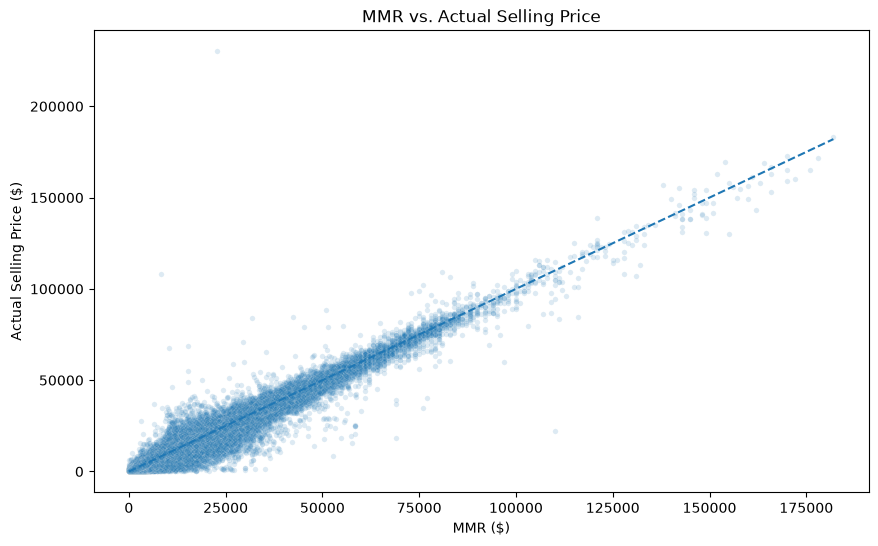

In [43]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cars,
    x="mmr",
    y="sellingprice",
    alpha=0.15,
    s=15
)

plt.plot(
    [0, cars["mmr"].max()],
    [0, cars["mmr"].max()],
    linestyle="--"
)

plt.title("MMR vs. Actual Selling Price")
plt.xlabel("MMR ($)")
plt.ylabel("Actual Selling Price ($)")

plt.show()

### MMR vs. Selling Price Visualization

The scatterplot shows that actual selling prices closely follow MMR values. Most vehicles cluster near the reference line where selling price equals MMR.

A small number of vehicles appear far above or below the line, showing that some transactions differ substantially from the market benchmark. These unusual differences may be caused by vehicle-specific factors, auction conditions, or remaining data-quality issues.

In [44]:
cars["price_vs_mmr"].quantile([
    0.01,
    0.05,
    0.25,
    0.50,
    0.75,
    0.95,
    0.99
])

0.01   -5600.0
0.05   -2700.0
0.25    -800.0
0.50     -50.0
0.75     650.0
0.95    2050.0
0.99    3700.0
Name: price_vs_mmr, dtype: float64

In [45]:
cars.loc[
    cars["price_vs_mmr"].abs().nlargest(20).index,
    [
        "year",
        "make",
        "model",
        "condition",
        "odometer",
        "mmr",
        "sellingprice",
        "price_vs_mmr"
    ]
].sort_values("price_vs_mmr")

,year,make,model,condition,odometer,mmr,sellingprice,price_vs_mmr
405316,2013,Mercedes-Benz,G-Class,4.8,23947.0,110000.0,22250.0,-87750.0
1723,2012,Mercedes-Benz,M-Class,NaN,1.0,69000.0,18500.0,-50500.0
404667,2015,Chevrolet,Tahoe,2.0,5210.0,52700.0,8500.0,-44200.0
505933,2014,Chevrolet,Corvette Stingray,4.5,12470.0,57600.0,15700.0,-41900.0
41815,2014,BMW,M5,NaN,1.0,76000.0,35000.0,-41000.0
401848,2014,Chevrolet,Corvette Stingray,4.0,13320.0,57500.0,19400.0,-38100.0
1565,2012,Mercedes-Benz,SL-Class,3.9,26776.0,58400.0,20500.0,-37900.0
68346,2014,Jaguar,XJ,1.0,9501.0,77000.0,40000.0,-37000.0
479480,2014,Land Rover,Range Rover,4.9,9925.0,97000.0,60000.0,-37000.0
409700,2015,GMC,Yukon,2.0,1.0,54700.0,18200.0,-36500.0


### MMR Deviation Findings

Most vehicles sell relatively close to their MMR values. The middle 50% of transactions fall between approximately $800 below MMR and $650 above MMR, while about 98% fall between $5,600 below and $3,700 above MMR.

A small number of transactions show extremely large differences between MMR and actual selling price. Several repeated VINs show one normal transaction and another extremely unusual transaction, suggesting that some extreme values may be data-entry errors rather than genuine market sales.

However, extreme MMR differences will not automatically be removed because some may represent legitimate unusual transactions, damaged vehicles, or special auction conditions.

In [46]:
extreme_mmr = cars.loc[
    cars["price_vs_mmr"].abs().nlargest(20).index,
    [
        "vin",
        "year",
        "make",
        "model",
        "condition",
        "odometer",
        "state",
        "seller",
        "mmr",
        "sellingprice",
        "price_vs_mmr",
        "saledate"
    ]
]

extreme_mmr.sort_values("price_vs_mmr")

,vin,year,make,model,condition,odometer,state,seller,mmr,sellingprice,price_vs_mmr,saledate
405316,wdcyc7df0dx200577,2013,Mercedes-Benz,G-Class,4.8,23947.0,pa,adcock brothers inc,110000.0,22250.0,-87750.0,2015-03-20 09:00:00+00:00
1723,4jgda7eb0ca049551,2012,Mercedes-Benz,M-Class,NaN,1.0,ca,high bid trading co inc,69000.0,18500.0,-50500.0,2014-12-18 20:00:00+00:00
404667,1gnscckcxfr548110,2015,Chevrolet,Tahoe,2.0,5210.0,fl,enterprise vehicle exchange / tra / rental / t...,52700.0,8500.0,-44200.0,2015-03-10 09:00:00+00:00
505933,1g1ym2d71e5101934,2014,Chevrolet,Corvette Stingray,4.5,12470.0,tx,pro financial inc,57600.0,15700.0,-41900.0,2015-06-03 10:20:00+00:00
41815,wbsfv9c52ed593067,2014,BMW,M5,NaN,1.0,tx,hertz/tra,76000.0,35000.0,-41000.0,2014-12-23 08:00:00+00:00
401848,1g1yf3d7xe5125570,2014,Chevrolet,Corvette Stingray,4.0,13320.0,fl,gm remarketing,57500.0,19400.0,-38100.0,2015-03-23 13:00:00+00:00
1565,wdbsk7ba3cf169124,2012,Mercedes-Benz,SL-Class,3.9,26776.0,ca,sports trend auto sales,58400.0,20500.0,-37900.0,2015-01-29 12:30:00+00:00
68346,sajwj2gd1e8v62687,2014,Jaguar,XJ,1.0,9501.0,wi,dollar thrifty damage liquidation,77000.0,40000.0,-37000.0,2015-02-04 09:30:00+00:00
479480,salgs2tf8ea184005,2014,Land Rover,Range Rover,4.9,9925.0,ca,land rover north america llc,97000.0,60000.0,-37000.0,2015-06-04 12:30:00+00:00
409700,1gks2bkc6fr297077,2015,GMC,Yukon,2.0,1.0,ny,hertz/tra,54700.0,18200.0,-36500.0,2015-05-06 09:00:00+00:00


In [47]:
extreme_vins = extreme_mmr["vin"]

cars[cars["vin"].isin(extreme_vins)][
    ["vin", "year", "make", "model", "mmr", "sellingprice", "seller"]
].sort_values("vin")

,vin,year,make,model,mmr,sellingprice,seller
90211,1fmcu0d77aka54695,2010,Ford,Escape,8650.0,9000.0,pat obrien chevrolet south
160201,1fmcu0d77aka54695,2010,Ford,Escape,8250.0,108200.0,pat obrien chevrolet south
344905,1fmcu9j98eua23833,2014,Ford,Escape,22800.0,230000.0,ford-lincoln dealer program
401848,1g1yf3d7xe5125570,2014,Chevrolet,Corvette Stingray,57500.0,19400.0,gm remarketing
505933,1g1ym2d71e5101934,2014,Chevrolet,Corvette Stingray,57600.0,15700.0,pro financial inc
409700,1gks2bkc6fr297077,2015,GMC,Yukon,54700.0,18200.0,hertz/tra
404667,1gnscckcxfr548110,2015,Chevrolet,Tahoe,52700.0,8500.0,enterprise vehicle exchange / tra / rental / t...
217865,1gnsckkc2fr197462,2015,Chevrolet,Suburban,53500.0,52500.0,enterprise veh exchange/rental
251360,1gnsckkc2fr197462,2015,Chevrolet,Suburban,15300.0,55000.0,music city autoplex llc
7873,1gnskjkc4fr158207,2015,Chevrolet,Suburban,11100.0,46400.0,enterprise veh exchange/rental


In [48]:
vin_summary = (
    cars.groupby("vin")
    .agg(
        records=("vin", "size"),
        min_price=("sellingprice", "min"),
        max_price=("sellingprice", "max"),
        min_mmr=("mmr", "min"),
        max_mmr=("mmr", "max")
    )
    .reset_index()
)

vin_summary["price_range"] = (
    vin_summary["max_price"] - vin_summary["min_price"]
)

vin_summary[
    vin_summary["records"] > 1
].sort_values("price_range", ascending=False).head(30)

,vin,records,min_price,max_price,min_mmr,max_mmr,price_range
57660,1fmcu0d77aka54695,2,9000.0,108200.0,8250.0,8650.0,99200.0
341976,4jgda7eb0ca049551,2,18500.0,62000.0,65000.0,69000.0,43500.0
338846,4f2yz04136km20229,2,2400.0,35000.0,3350.0,8500.0,32600.0
373232,5n1aa0nc2cn612501,2,700.0,31600.0,8125.0,30300.0,30900.0
513736,wbakp9c55ed692446,2,31000.0,59250.0,31600.0,64000.0,28250.0
2024,19uua9f53da001179,2,4750.0,29600.0,21100.0,29400.0,24850.0
236712,2cndl13f056137366,2,3300.0,27500.0,3250.0,3550.0,24200.0
36732,1fadp3f28dl183181,2,12300.0,35200.0,11250.0,35100.0,22900.0
522990,wby2z2c57evx64633,2,138500.0,160000.0,145000.0,172000.0,21500.0
71503,1fmjk1j56eef32888,2,11200.0,32100.0,32000.0,32300.0,20900.0


In [49]:
top_repeat_vins = (
    vin_summary[
        vin_summary["records"] > 1
    ]
    .sort_values("price_range", ascending=False)
    .head(10)["vin"]
)

cars[cars["vin"].isin(top_repeat_vins)][
    [
        "vin",
        "saledate",
        "year",
        "make",
        "model",
        "condition",
        "odometer",
        "mmr",
        "sellingprice",
        "seller"
    ]
].sort_values(["vin", "saledate"])

,vin,saledate,year,make,model,condition,odometer,mmr,sellingprice,seller
157181,19uua9f53da001179,2015-01-16 09:00:00+00:00,2013,Acura,TL,3.8,13146.0,29400.0,29600.0,ahfc/honda lease trust/hvt inc acuras
30893,19uua9f53da001179,2015-04-10 09:00:00+00:00,2013,Acura,TL,2.9,1.0,21100.0,4750.0,ahfc/honda lease trust/hvt inc.
172475,1fadp3f28dl183181,2015-01-28 10:00:00+00:00,2013,Ford,Focus,4.8,26336.0,11250.0,12300.0,ford motor credit company llc
164603,1fadp3f28dl183181,2015-05-21 09:30:00+00:00,2013,Ford,Focus,4.8,26329.0,35100.0,35200.0,ford motor credit company llc
90211,1fmcu0d77aka54695,2015-01-13 17:30:00+00:00,2010,Ford,Escape,3.7,82980.0,8650.0,9000.0,pat obrien chevrolet south
160201,1fmcu0d77aka54695,2015-01-20 09:30:00+00:00,2010,Ford,Escape,3.7,82985.0,8250.0,108200.0,pat obrien chevrolet south
130687,1fmjk1j56eef32888,2015-02-04 10:00:00+00:00,2014,Ford,Expedition,4.9,33137.0,32300.0,32100.0,avis budget group
419638,1fmjk1j56eef32888,2015-05-13 10:00:00+00:00,2014,Ford,Expedition,4.6,34364.0,32000.0,11200.0,ford-lincoln dealer program
4158,2cndl13f056137366,2014-12-18 20:00:00+00:00,2005,Chevrolet,Equinox,NaN,NaN,3250.0,27500.0,buena park honda
7231,2cndl13f056137366,2014-12-18 20:00:00+00:00,2005,Chevrolet,Equinox,NaN,125141.0,3550.0,3300.0,buena park honda


### Next Step

Investigate repeated VINs with unusually large differences in selling price.

The goal is to determine whether these represent legitimate repeat sales or likely data-quality issues before deciding whether any extreme transactions should be excluded from modeling.